# Análisis ConnectaTel


--- 
## 🧩 Paso 1: Cargar y explorar

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.


In [72]:
# importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [73]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [74]:
# mostrar las primeras 5 filas de plans
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [75]:
# mostrar las primeras 5 filas de users
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [76]:
# mostrar las primeras 5 filas de usage
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


## 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.


In [77]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users",users.shape)
print("usage",usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [78]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [79]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [80]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.


In [81]:
# cantidad de nulos para users
print('Cantidad de valores nulos:', users.isna().sum())

print('Proporción de valores nulos :',(users.isna().sum()/4000)*100)

Cantidad de valores nulos: user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
Proporción de valores nulos : user_id        0.000
first_name     0.000
last_name      0.000
age            0.000
city          11.725
reg_date       0.000
plan           0.000
churn_date    88.350
dtype: float64


In [82]:
# cantidad de nulos para usage

print('Cantidad de valores nulos:', usage.isna().sum())

print('Proporción de valores nulos :',(usage.isna().sum()/4000)*100)

Cantidad de valores nulos: id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
Proporción de valores nulos : id            0.00
user_id       0.00
type          0.00
date          1.25
duration    551.90
length      447.40
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?

- **DF USERS**

Las columnas que presentan mayor cantidad de datos nulos son: "churn_date" y "city", con una proporción de 88.350 y 11.725, respectivamente

- **DF USAGE**

Las columnas que presentan mayor cantidad de datos nulos son:"duration", "length" y "date" con una proporción de  551.90, 447.40 y 1.25, respectivamente

- Indica qué harías: ¿imputar, eliminar, ignorar?

Para el caso de los valores nulos en **DF USERS**:

"churn_date" --- ignoro ó le asigno otro valor sea texto ó booleano, con la finalidad de analizar que información puedo extraer de este dato (posiblemente la porcentaje de retención de usuario, ó similar)

"city" --- consideraría dejarlos como nulos ó atribuirle un valor de "no identificado"

Para el caso de los valores nulos en **DF USAGE**:

"duration" y "length" --- ignoro teniendo en cuenta que de acuerdo a lo que se observa, los valores de duration están dado para CALL y los valores de length para text

"date" --- teniendo en cuenta que representa solo el 1.25% de los datos, lo imputaria con la mediana

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.


In [83]:
# explorar columnas numéricas de users

col_numerics=["user_id","age"]

In [84]:
def stat_sum (df,col):
    return df[col].describe()

print(stat_sum(users,col_numerics))


            user_id          age
count   4000.000000  4000.000000
mean   11999.500000    33.739750
std     1154.844867   123.232257
min    10000.000000  -999.000000
25%    10999.750000    32.000000
50%    11999.500000    47.000000
75%    12999.250000    63.000000
max    13999.000000    79.000000


**Observaciones**

- La columna `user_id` los valores para user_id están datos entre 10000 a 13999 y no hay ningun dato sentinels
- La columna `age` **hay datos sentinels (-999)**

In [85]:
# explorar columnas numéricas de usage

col_numerics=["id","user_id","duration","length"]

In [86]:
def stat_sum (df,col):
    return df[col].describe()

print(stat_sum(usage,col_numerics))

                id       user_id      duration        length
count  40000.00000  40000.000000  17924.000000  22104.000000
mean   20000.50000  12002.405975      5.202237     52.127398
std    11547.14972   1157.279564      6.842701     56.611183
min        1.00000  10000.000000      0.000000      0.000000
25%    10000.75000  10996.000000      1.437500     37.000000
50%    20000.50000  12013.000000      3.500000     50.000000
75%    30000.25000  13005.000000      6.990000     64.000000
max    40000.00000  13999.000000    120.000000   1490.000000


**Observaciones**

- Las columnas `id` y `user_id` Los valores para user_id están datos entre 10000 a 13999, no hay valores sentinels
- Las columnas 'duration' y ´length´ no hay valores sentinels

In [87]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']


In [88]:
def stat_sum (df,col):
    return df[col].describe()

print(stat_sum(users,columnas_user))

          city    plan
count     3531    4000
unique       7       2
top     Bogotá  Basico
freq       808    2595


**Observaciones**

- La columna `city` existen 7 valores únicos y el valor que mas se repite es Bogotá, por tanto es la ciudad donde mas usuarios reportan datos en este df (ciudad con mas clientes)
- La columna `plan` existe 2 valores únicos y el valor que mas se repite es Básico Por tanto es el plan con mas utilizado por los usuarios analizados

In [89]:
# explorar columna categórica de usage
usage['type'].describe()

count     40000
unique        2
top        text
freq      22092
Name: type, dtype: object

**Observaciones**

- La columna `type` existen 2 valores únicos, y el valor que mas se repite es text. Por tanto es el uso mas común


---

✍️ **Comentario**

La columna "age" tiene datos sentinels 

se debe **Imputar con la mediana**

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.


In [90]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users["reg_date"], errors="coerce")


In [91]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage["date"], errors="coerce")

In [92]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.unique()

array([2022, 2026, 2023, 2024])

**Observaciones**

En `reg_date`,  hay datos con fechas del 2026,  lo cual de acuerdo a lo establecido para el presente analisis, no se tendrá en cuenta
Basaremos el análisis en estas fechas (2022,2023, 2024)

In [93]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.unique()

array([2024.,   nan])

**Observaciones**

En `date`, hay datos nan

✍️ **Comentario**

  Aparecen datos del 2026

  Ignorar, teniendo en cuenta que el análisis se desarrollará con los datos hasta el 2024, de acuerdo a lo indicado al iniciar el proyecto.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [94]:
# Reemplazar -999 por la mediana de age
age_mediana = users['age'].median()
users['age'] = users['age'].replace(-999, np.nan)
users['age'] = users['age'].fillna(age_mediana)


# Verificar cambios
users['age'].describe()


count    4000.000000
mean       48.122250
std        17.690408
min        18.000000
25%        33.000000
50%        47.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [95]:
# Reemplazar ? por NA en city

users['city'] = users['city'].replace("?", "NA")
# Verificar cambios
users['city'].head()


0    Medellín
1          NA
2        CDMX
3      Bogotá
4         GDL
Name: city, dtype: object

In [96]:
# Marcar fechas futuras como NA para reg_date

users['reg_date'] = users['reg_date'].dt.year



# Verificar cambios
users.head()


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38.0,Medellín,2022,Basico,NaN
1,10001,Mateo,Torres,53.0,NA,2022,Basico,NaN
2,10002,Sofia,Ramirez,57.0,CDMX,2022,Basico,NaN
3,10003,Mateo,Ramirez,69.0,Bogotá,2022,Premium,NaN
4,10004,Mateo,Torres,63.0,GDL,2022,Basico,NaN


In [97]:
users['reg_date'] =users['reg_date'].replace(2026, pd.NA)

In [98]:
users['reg_date'].unique()


array([2022, <NA>, 2023, 2024], dtype=object)

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [99]:
# Verificación MAR en usage (Missing At Random) para duration
usage["duration"].isna().sum()

22076

In [100]:
usage["duration"].isna().groupby(usage["type"]).sum()

type
call        0
text    22076
Name: duration, dtype: int64

In [101]:
# Verificación MAR en usage (Missing At Random) para length
usage["length"].isna().sum()

17896

In [102]:
usage["length"].isna().groupby(usage["type"]).sum()

type
call    17896
text        0
Name: length, dtype: int64

**Observación**

Los nulos en `duration` y `length`: dependende de otra variable, en este caso "TYPE" por tanto, es tipo MAR y se dejan como nulos

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 


In [103]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg({'is_text':'sum','is_call': 'sum','duration': 'sum'}).reset_index()

# observar resultado
usage_agg.head(10)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74
3,10003,11,3,8.99
4,10004,4,3,8.01
5,10005,5,7,44.97
6,10006,3,5,28.39
7,10007,3,5,30.23
8,10008,5,5,28.85
9,10009,5,3,5.99


In [104]:
# Renombrar columnas
usage_agg=usage_agg.rename(columns={"is_text":"cant_mensajes","is_call":"cant_llamadas","duration":"cant_minutos_llamada"})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [105]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = pd.merge(users,usage_agg,on=["user_id"],how="inner").sort_values(by="user_id",ascending=True) 
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022,Basico,NaN,7,3,23.70
1,10001,Mateo,Torres,53.0,NA,2022,Basico,NaN,5,10,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022,Basico,NaN,5,2,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022,Premium,NaN,11,3,8.99
4,10004,Mateo,Torres,63.0,GDL,2022,Basico,NaN,4,3,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.



In [106]:
# Resumen estadístico de las columnas numéricas
user_profile.describe()

,user_id,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000,3999.000000,3999.000000
mean,11999.729432,48.124531,5.524381,4.478120,23.317054
std,1154.898108,17.692032,2.358416,2.144238,18.168095
min,10000.000000,18.000000,0.000000,0.000000,0.000000
25%,10999.500000,33.000000,4.000000,3.000000,11.120000
50%,12000.000000,47.000000,5.000000,4.000000,19.780000
75%,12999.500000,63.000000,7.000000,6.000000,31.415000
max,13999.000000,79.000000,17.000000,15.000000,155.690000


In [107]:
# Distribución porcentual del tipo de plan
distri_porcen = user_profile['plan'].value_counts(normalize=True) * 100
print(distri_porcen)


Basico     64.866217
Premium    35.133783
Name: plan, dtype: float64


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.


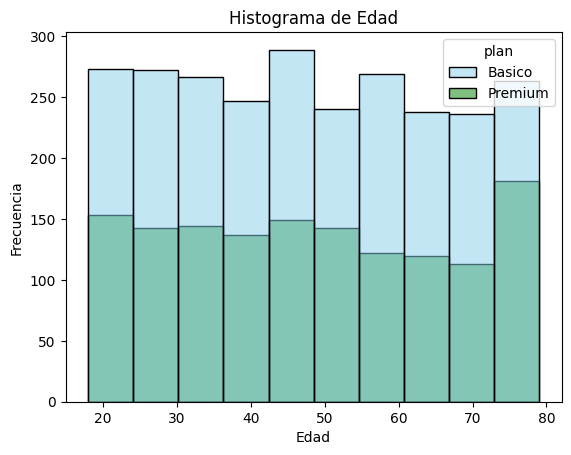

In [108]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile,x ="age",hue='plan',bins=10,palette=['skyblue','green'])
plt.title('Histograma de Edad')
plt.xlabel('Edad')
plt.ylabel('Frecuencia')
plt.show()

💡Insights: 
- Distribución: Se observa que es simétrica en general ahora bien, para los usuarios con edades entre 73 - 79 aprox, la frecuencia cambia, observandose mayor proporción de plan premium

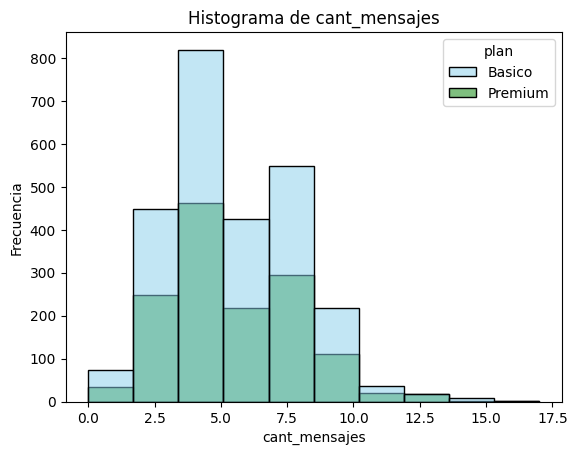

In [109]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile,x ="cant_mensajes",hue='plan',bins=10,palette=['skyblue','green'])
plt.title('Histograma de cant_mensajes')
plt.xlabel('cant_mensajes')
plt.ylabel('Frecuencia')
plt.show()

💡Insights: 
- La cantidad de mensajes se concentra entre valores de 1-10 mensajes, y muy poca cantidad de msj cercans a 15, por lo cual se observa una distribución sesgada a la derecha, 

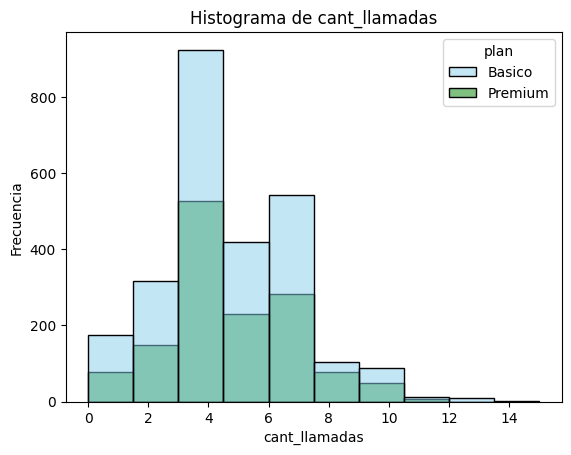

In [110]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile,x ="cant_llamadas",hue='plan',bins=10,palette=['skyblue','green'])
plt.title('Histograma de cant_llamadas')
plt.xlabel('cant_llamadas')
plt.ylabel('Frecuencia')
plt.show()

💡Insights: 
 La cantidad de mensajes se concentra  entre valores de 1-10 , y muy poca cantidad de mmadas cercanos a 14, por lo cual se observa una distribución sesgada a la derecha

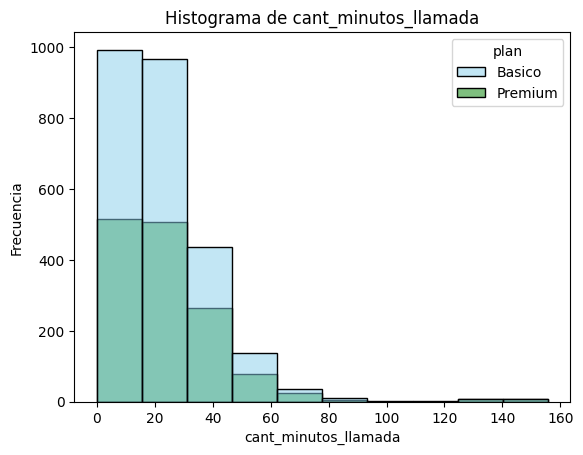

In [111]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile,x ="cant_minutos_llamada",hue='plan',bins=10,palette=['skyblue','green'])
plt.title('Histograma de cant_minutos_llamada')
plt.xlabel('cant_minutos_llamada')
plt.ylabel('Frecuencia')
plt.show()


💡Insights: 
- Se observa una distribución muy sesgada a la derecha,  con la duración de llamadas entre 12 a 45 min

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.


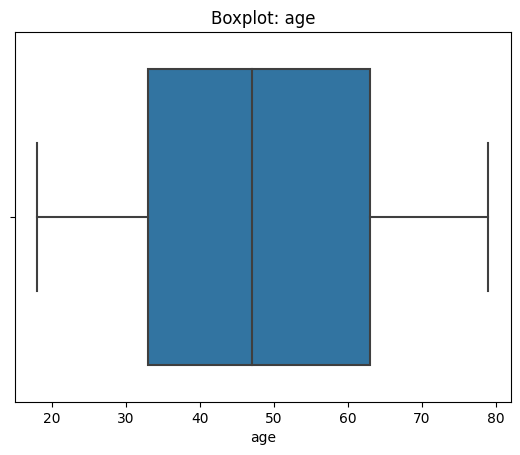

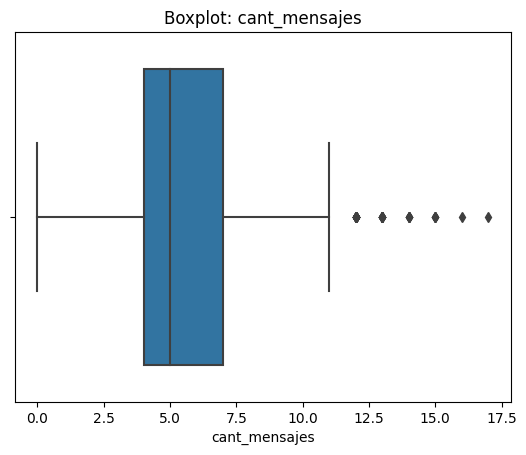

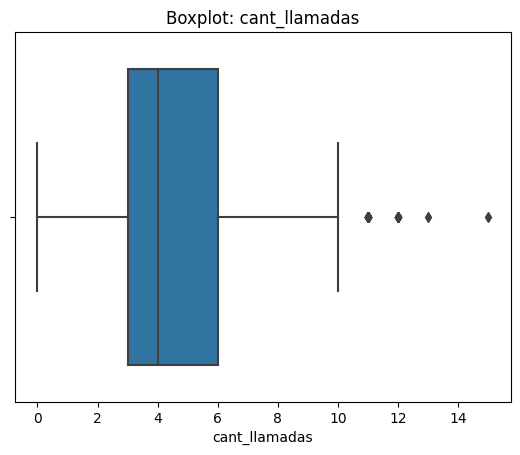

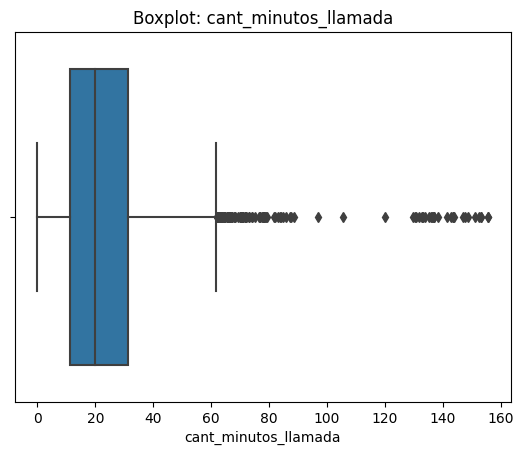

In [112]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(data=user_profile, x=col)
    plt.title(f'Boxplot: {col}')
    plt.show()
    

    

💡Insights: 
- Age: ...no presenta outliers
- cant_mensajes: SI presenta outliers
- cant_llamadas: SI presenta outliers
- cant_minutos_llamada: SI presenta outliers

In [113]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    Q1=user_profile[col].quantile(0.25)
    Q3=user_profile[col].quantile(0.75)
    IQR=Q3-Q1
    upper= Q3 + 1.5 * IQR
    print(f"Columna: {col}")
    print("Q1:", Q1, "Q3:", Q3, "IQR:", IQR, "Upper:", upper)
    print("-" * 50)
    

Columna: cant_mensajes
Q1: 4.0 Q3: 7.0 IQR: 3.0 Upper: 11.5
--------------------------------------------------
Columna: cant_llamadas
Q1: 3.0 Q3: 6.0 IQR: 3.0 Upper: 10.5
--------------------------------------------------
Columna: cant_minutos_llamada
Q1: 11.12 Q3: 31.415 IQR: 20.295 Upper: 61.8575
--------------------------------------------------


In [114]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué? **No se deben** mantener ya que de acuerdo con los  que se observa en el histograma son muy pocos los datos que superan el valor máximo, por tanto la proporción de los mismos no es significativa en el universo de la totalidad de los datos
- cant_llamadas: mantener o no outliers, porqué? **No se deben** mantener ya que de acuerdo con los  que se observa en el histograma son muy pocos los datos que superan el valor máximo, por tanto la proporción de los mismos no es significativa en el universo de la totalidad de los datos
- cant_minutos_llamada: mantener o no outliers, porqué? **se podrían mantener** y evaluar si existe alguna información que se pueda analizar para los datos que superan el límite superior

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Segmentación establecida por uso:**
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [115]:
# Crear columna grupo_uso
user_profile["grupo_uso"]= np.where(
    (user_profile["cant_llamadas"]<5) & (user_profile["cant_mensajes"]<5),'Bajo uso',
    np.where((user_profile["cant_llamadas"]<10)&(user_profile["cant_mensajes"]<10),'Uso medio',
             "Alto uso"
            )
)


In [116]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022,Basico,NaN,7,3,23.70,Uso medio
1,10001,Mateo,Torres,53.0,NA,2022,Basico,NaN,5,10,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022,Basico,NaN,5,2,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022,Premium,NaN,11,3,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022,Basico,NaN,4,3,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.



**Segmentación establecida por edades:**

  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [117]:
# Crear columna grupo_edad
user_profile["grupo_edad"]= np.where(
    (user_profile["age"]<30),'Joven',
    np.where((user_profile["age"]<60),'Adulto',
             "Adulto mayor"
            )
)


In [118]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022,Basico,NaN,7,3,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,NA,2022,Basico,NaN,5,10,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022,Basico,NaN,5,2,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022,Premium,NaN,11,3,8.99,Alto uso,Adulto mayor
4,10004,Mateo,Torres,63.0,GDL,2022,Basico,NaN,4,3,8.01,Bajo uso,Adulto mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.


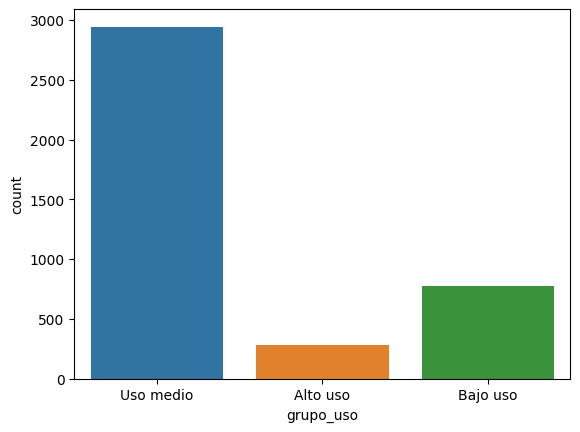

In [119]:
# Visualización de los segmentos por uso

sns.countplot(data=user_profile, x="grupo_uso")

plt.show()


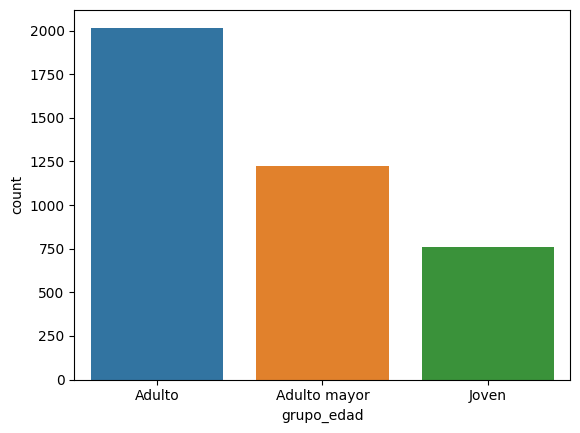

In [120]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x="grupo_edad")

plt.show()


### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- **Valores nulos**

En todos los DF habían valores de este tipo:

**DF USER**:  Presentaba valores nulos en las columnas "churn_date" y "city”, en una proporción de 88.350 y 11.725, respectivamente

**DF USAGE:** Presentaba valores nulos en las columnas "duration", "length" y "date”, en una proporción de  551.90, 447.40 y 1.25, respectivamente.

- **Valores inválidos ó sentinels**

**DF USER**: 

1. Presentaba valores sentinels (-999) en la columna “Age”
2. Presentaba datos para año 2026 (fuera del rango de fechas con base en las cuales se realizó el análisis)
3. En la columna “ city” había valores de “?”


🔍 **Segmentos por Edad**
Con base en la segmentación etaria de los clientes de ConnectaTel, se definieron tres grupos: jóvenes (menores de 30 años), adultos (entre 30 y 59 años) y adultos mayores (60 años o más).

El análisis evidencia que la mayor proporción de clientes se concentra en el segmento de adultos, con aproximadamente 2.000 usuarios, lo que representa el principal grupo poblacional de la empresa. En segundo lugar, se encuentra el segmento de adultos mayores, con cerca de 1.250 clientes. Finalmente, el grupo de jóvenes registra la menor participación dentro de la base de usuarios.

Estos resultados permiten identificar que la cartera de clientes de ConnectaTel está compuesta principalmente por usuarios adultos y adultos mayores, información clave para orientar estrategias comerciales, de comunicación y de fidelización adaptadas a las necesidades de estos segmentos.

📊 **Segmentos por Nivel de Uso**

De acuerdo con el nivel de uso de los servicios, los clientes de ConnectaTel fueron segmentados en tres categorías: bajo uso (menos de 5 mensajes y llamadas), uso medio (menos de 10 mensajes y llamadas) y alto uso (más de 10 interacciones).

El análisis muestra que la mayoría de los clientes se concentra en el segmento de uso medio, con aproximadamente 3.000 usuarios, lo que representa cerca del 75% del total de la base analizada, compuesta por 4.000 clientes durante el periodo 2024. En consecuencia, el porcentaje restante corresponde a usuarios con niveles de uso alto o bajo.

Adicionalmente, al relacionar esta información con la segmentación por edades, se identifica que cerca del 50% de los clientes corresponde al grupo de adultos (menores de 60 años), mientras que los adultos mayores representan aproximadamente el 31% de la base de usuarios. Ambos segmentos presentan predominantemente un nivel de uso medio de los servicios.

En este contexto, los segmentos de adultos y adultos mayores se consolidan como los grupos más relevantes para ConnectaTel, ya que en conjunto representan alrededor del 75% de los usuarios analizados. Este hallazgo constituye una base estratégica para orientar acciones comerciales, programas de fidelización y campañas de comunicación enfocadas en las necesidades y hábitos de consumo de estos clientes.

💡 **Recomendaciones**


- Considerando que, dentro del análisis realizado, se identificó un máximo aproximado de 17 mensajes y 156 minutos en llamadas por usuario, se recomienda a ConnectaTel diseñar nuevos planes dentro de su portafolio de servicios. El objetivo es alinear la oferta comercial con los patrones reales de consumo de los clientes, permitiendo una mayor personalización de los servicios y una mejor experiencia de usuario.

- Asimismo, se evidenció la presencia de valores atípicos (outliers) en la duración de las llamadas, lo que indica la existencia de un nicho específico de clientes con necesidades de consumo superiores al promedio. En este sentido, se recomienda desarrollar planes especializados dirigidos a este segmento, incorporando mayores beneficios en minutos de llamada y condiciones diferenciadas que respondan a sus hábitos de uso.

- Estas estrategias permitirían a ConnectaTel optimizar su portafolio de servicios, fortalecer la fidelización de clientes y generar oportunidades de incremento en ingresos mediante ofertas más ajustadas a los distintos perfiles de consumo identificados en el análisis.


---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`